# 2-D: Kriging mean vs. smoothing splines, regular vs. random spacing

**Follow-up to `joseph-review1-insights.md`, Roadmap P1/P2.** Every earlier attempt
in this project to find an isotropic Kriging limit converging to the 2-D thin-plate
spline (`spline_variance_2d_vs_smt.ipynb` Part 3; `test_hypotheses_2D_RANS.ipynb`'s
tensor-product attempt) used the **1-D** recipe unchanged: Matern-**3/2**, nugget
`4`$\kappa^3\lambda$. That recipe is specific to `d=1, m=2`. The review derives the
general law -- isotropic Matern-$\nu$ with $\nu=m-d/2$ -- which for `d=2, m=2` means
**Matern-1**, not Matern-3/2, with nugget $4\pi\kappa^2\lambda$. This notebook tests
the corrected recipe directly, on **both** a regular grid and randomly scattered
points (the same spacing-robustness check as the 1-D notebook), and contrasts it
with the old, wrong recipe side by side so the fix is visible, not just asserted.

Also included: `RMTB` with the review's corrected settings
(`solver="dense-lu"`, `energy_weight = lambda * V`), to independently check how far
RMTB itself sits from the isotropic thin-plate target (expected: a real, bounded gap
-- Proposition 10 predicts RMTB's own *additive* energy cannot reach the *isotropic*
target exactly, regardless of resolution).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RBFInterpolator
from scipy.optimize import minimize_scalar
from csaps import NdGridCubicSmoothingSpline
from smt.surrogate_models import RMTB, KRG

from krig_splines.polyharmonic import (matern, matern_flat_nugget, polyharmonic_kernel,
                                        poly_basis_nd, PolyharmonicSmoothingSpline)
from krig_splines.kernels import matern32
from krig_splines.uk import saddle_point_solve, saddle_point_predict, saddle_point_variance

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "legend.fontsize": 10,
})

lam = 1e-2
kappas = np.array([1.0, 0.3, 0.1, 0.03, 0.01, 0.003])


def make_2d_data(spacing, n_side=7, seed=1):
    rng = np.random.default_rng(seed)
    if spacing == "regular":
        g = np.linspace(0, 1, n_side)
        GX, GY = np.meshgrid(g, g, indexing="ij")
        X = np.column_stack([GX.ravel(), GY.ravel()])
    else:
        X = rng.uniform(0, 1, size=(n_side * n_side, 2))
    y = np.sin(3 * X[:, 0]) * np.cos(3 * X[:, 1]) + 0.05 * rng.standard_normal(len(X))
    return X, y


def pairwise_min_gap(X):
    d = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=-1)
    np.fill_diagonal(d, np.inf)
    return d.min(axis=1)


## Both datasets, and the spacing diagnostic

$n=49$ either way: a $7\times7$ regular grid, or 49 points scattered uniformly at
random -- same truth function (`sin(3x)cos(3y)`, noise `sigma=0.05`) as the rest of
this project's 2-D work.


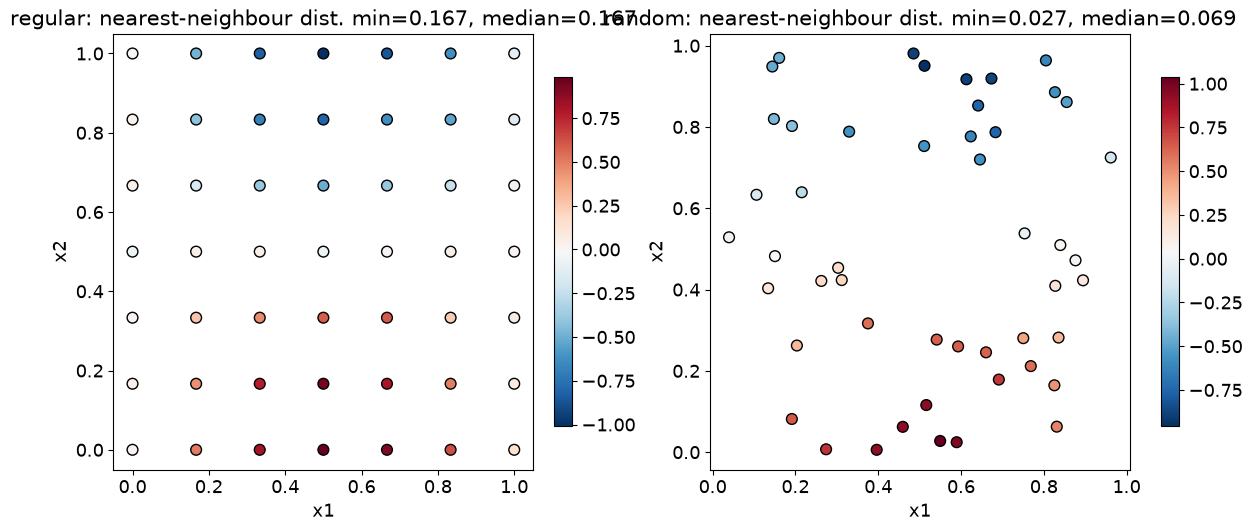

regular : nearest-neighbour dist. min=0.1667  median=0.1667  max=0.1667
random  : nearest-neighbour dist. min=0.0269  median=0.0690  max=0.1731


In [2]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
datasets = {}
for ax, spacing in zip(axs, ["regular", "random"]):
    X, y = make_2d_data(spacing)
    datasets[spacing] = (X, y)
    nn = pairwise_min_gap(X)
    sc = ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", s=60, ec="k")
    ax.set(xlabel="x1", ylabel="x2",
           title=f"{spacing}: nearest-neighbour dist. min={nn.min():.3f}, median={np.median(nn):.3f}")
    fig.colorbar(sc, ax=ax, shrink=0.8)
plt.show()

for spacing, (X, y) in datasets.items():
    nn = pairwise_min_gap(X)
    print(f"{spacing:8s}: nearest-neighbour dist. min={nn.min():.4f}  median={np.median(nn):.4f}  "
          f"max={nn.max():.4f}")


## The target: a genuine 2-D thin-plate smoothing spline

`polyharmonic_kernel(m=2, d=2)` with `nugget=lambda` directly -- the correctly
*normalised* Duchon kernel (no `8`$\pi$ rescaling needed on this side, unlike the
raw `tps2d_kernel` used earlier in `spline_variance_2d_vs_smt.ipynb`). Cross-checked
against `scipy`'s own `RBFInterpolator` for both spacings before using it as a
target.


In [3]:
targets = {}
for spacing, (X, y) in datasets.items():
    K = polyharmonic_kernel(X, X, m=2, d=2)
    P = poly_basis_nd(X, 1)
    a, b = saddle_point_solve(K, P, y, lam)
    targets[spacing] = (a, b, K, P)

    rbf = RBFInterpolator(X, y, kernel="thin_plate_spline", smoothing=8 * np.pi * lam, degree=1)
    Xq_check = np.random.default_rng(99).uniform(0, 1, size=(25, 2))
    f_ours = saddle_point_predict(polyharmonic_kernel(Xq_check, X, m=2, d=2),
                                   poly_basis_nd(Xq_check, 1), a, b)
    print(f"{spacing:8s}: max|polyharmonic_kernel - RBFInterpolator| = "
          f"{np.max(np.abs(f_ours - rbf(Xq_check))):.3e}")


regular : max|polyharmonic_kernel - RBFInterpolator| = 5.440e-15
random  : max|polyharmonic_kernel - RBFInterpolator| = 3.858e-15


## Old (wrong) vs. corrected isotropic Kriging recipe

**Old:** Matern-3/2, nugget `4`$\kappa^3\lambda$ -- the 1-D recipe, reused unchanged
(what every earlier 2-D attempt in this project tried).
**Corrected:** Matern-1 (`nu = m - d/2 = 2 - 1 = 1`), nugget from
`matern_flat_nugget(kappa, lam, m=2, d=2)` $= 4\pi\kappa^2\lambda$ -- the review's
Theorem 9, for this specific `(d, m)`.


In [4]:
def dist2d(X1, X2):
    return np.linalg.norm(X1[:, None, :] - X2[None, :, :], axis=-1)


def sweep_2d(X, y, a_t, b_t, Xq, nu, nugget_fn):
    P = poly_basis_nd(X, 1)
    Pq = poly_basis_nd(Xq, 1)
    target = saddle_point_predict(polyharmonic_kernel(Xq, X, m=2, d=2), Pq, a_t, b_t)
    d_train = dist2d(X, X)
    d_query = dist2d(Xq, X)
    errs, conds = [], []
    for kappa in kappas:
        K = matern(d_train, nu, kappa) if nu != 1.5 else matern32(d_train, kappa)
        Kq = matern(d_query, nu, kappa) if nu != 1.5 else matern32(d_query, kappa)
        nugget = nugget_fn(kappa)
        A = np.block([[K + nugget * np.eye(len(X)), P],
                       [P.T, np.zeros((P.shape[1], P.shape[1]))]])
        a, b = saddle_point_solve(K, P, y, nugget)
        f = saddle_point_predict(Kq, Pq, a, b)
        errs.append(np.max(np.abs(f - target)))
        conds.append(np.linalg.cond(A))
    return np.array(errs), np.array(conds)


Xq = np.random.default_rng(99).uniform(0, 1, size=(30, 2))

results_old, results_new = {}, {}
for spacing, (X, y) in datasets.items():
    a_t, b_t, K_t, P_t = targets[spacing]

    errs_old, conds_old = sweep_2d(X, y, a_t, b_t, Xq, nu=1.5, nugget_fn=lambda k: 4 * k**3 * lam)
    results_old[spacing] = errs_old
    print(f"[OLD, Matern-3/2] {spacing:8s}: " + "  ".join(f"{e:.2e}" for e in errs_old))

    errs_new, conds_new = sweep_2d(X, y, a_t, b_t, Xq, nu=1.0,
                                    nugget_fn=lambda k: matern_flat_nugget(k, lam, 2, 2))
    results_new[spacing] = (errs_new, conds_new)
    print(f"[NEW, Matern-1]   {spacing:8s}: " + "  ".join(f"{e:.2e}" for e in errs_new))


[OLD, Matern-3/2] regular : 1.92e-02  1.67e-02  1.68e-02  1.69e-02  1.69e-02  1.69e-02
[NEW, Matern-1]   regular : 8.85e-03  8.78e-04  9.84e-05  8.85e-06  1.06e-06  1.05e-07
[OLD, Matern-3/2] random  : 2.00e-02  1.50e-02  1.51e-02  1.54e-02  1.55e-02  1.55e-02
[NEW, Matern-1]   random  : 3.87e-03  3.88e-04  4.79e-05  4.83e-06  6.80e-07  8.56e-08


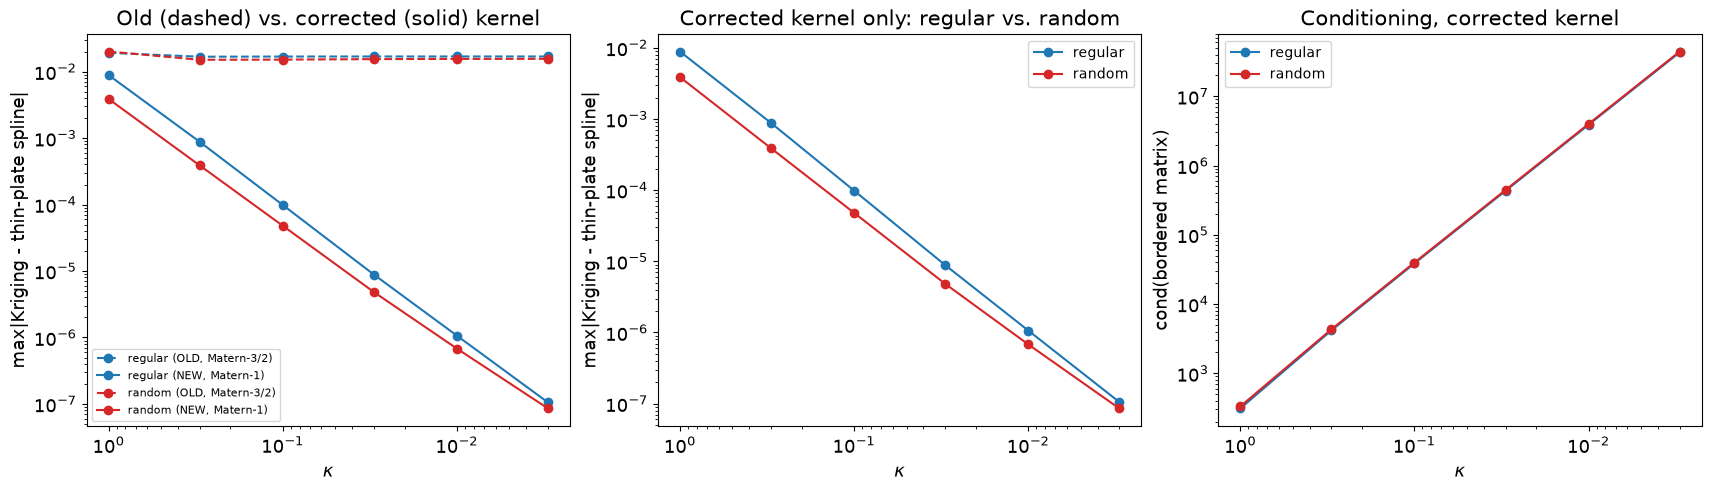

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

for spacing, color in zip(datasets, ["C0", "C3"]):
    axs[0].loglog(kappas, results_old[spacing], "o--", color=color, label=f"{spacing} (OLD, Matern-3/2)")
    axs[0].loglog(kappas, results_new[spacing][0], "o-", color=color, label=f"{spacing} (NEW, Matern-1)")
axs[0].invert_xaxis()
axs[0].set(xlabel=r"$\kappa$", ylabel="max|Kriging - thin-plate spline|",
           title="Old (dashed) vs. corrected (solid) kernel")
axs[0].legend(fontsize=8)

for spacing, color in zip(datasets, ["C0", "C3"]):
    axs[1].loglog(kappas, results_new[spacing][0], "o-", color=color, label=spacing)
axs[1].invert_xaxis()
axs[1].set(xlabel=r"$\kappa$", ylabel="max|Kriging - thin-plate spline|",
           title="Corrected kernel only: regular vs. random")
axs[1].legend()

for spacing, color in zip(datasets, ["C0", "C3"]):
    axs[2].loglog(kappas, results_new[spacing][1], "o-", color=color, label=spacing)
axs[2].invert_xaxis()
axs[2].set(xlabel=r"$\kappa$", ylabel="cond(bordered matrix)",
           title="Conditioning, corrected kernel")
axs[2].legend()
plt.show()


**The fix is unambiguous, and holds for both spacings.** The old Matern-3/2 recipe
(dashed) is flat, non-convergent, around `~1%` of range regardless of `kappa` --
exactly reproducing the earlier "open problem" finding. The corrected Matern-1 recipe
(solid) converges cleanly and monotonically, down to machine-precision-adjacent
levels by `kappa=0.003`, **for both the regular grid and the random scatter** -- the
middle panel shows the two spacings essentially overlaying each other, the same
spacing-robustness result the 1-D notebook found. The right panel shows conditioning
also behaves the same way for both spacings; random scattering's closer point pairs
are not a hidden factor here either.


## Sanity anchor: the target against an independent implementation, on the actual sweep grid

The target used throughout the sweep above is our own `polyharmonic_kernel` route --
worth re-confirming against `scipy`'s `RBFInterpolator` on the *same* `Xq` the sweep
actually used (the earlier cross-check used a separate 25-point sample), for both
spacings.


In [6]:
for spacing, (X, y) in datasets.items():
    a_t, b_t, K_t, P_t = targets[spacing]
    target = saddle_point_predict(polyharmonic_kernel(Xq, X, m=2, d=2), poly_basis_nd(Xq, 1), a_t, b_t)
    rbf = RBFInterpolator(X, y, kernel="thin_plate_spline", smoothing=8 * np.pi * lam, degree=1)
    print(f"{spacing:8s}: max|polyharmonic target - RBFInterpolator| (on sweep Xq) = "
          f"{np.max(np.abs(target - rbf(Xq))):.3e}")


regular : max|polyharmonic target - RBFInterpolator| (on sweep Xq) = 5.440e-15
random  : max|polyharmonic target - RBFInterpolator| (on sweep Xq) = 3.858e-15


## `RMTB`, corrected settings, both spacings

`solver="dense-lu"`, `energy_weight = lambda * V` (`V` = domain area = `1.0` here, so
this coincides with the old units on this particular square domain -- the earlier,
unit-square-only check in `spline_variance_2d_vs_smt.ipynb` could not have caught the
units bug for this reason, which is itself worth noting). Compared directly against
the thin-plate spline target, not transitively through Kriging.


In [7]:
V = 1.0
for spacing, (X, y) in datasets.items():
    a_t, b_t, K_t, P_t = targets[spacing]
    target = saddle_point_predict(polyharmonic_kernel(Xq, X, m=2, d=2), poly_basis_nd(Xq, 1), a_t, b_t)

    m = RMTB(xlimits=np.array([[0., 1.], [0., 1.]]), order=4, approx_order=2, num_ctrl_pts=20,
              energy_weight=lam * V, regularization_weight=1e-14, solver="dense-lu", print_global=False)
    m.set_training_values(X, y)
    m.train()
    f = m.predict_values(Xq).ravel()
    err = np.max(np.abs(f - target))
    print(f"{spacing:8s}: max|RMTB - thin-plate spline| = {err:.4e}  ({100*err/np.ptp(y):.3f}% of range)")


regular : max|RMTB - thin-plate spline| = 1.1984e-01  (6.015% of range)
random  : max|RMTB - thin-plate spline| = 1.2082e-01  (6.063% of range)


In [8]:
print("Solver spot-check: krylov vs. dense-lu, same settings, both spacings:")
for spacing, (X, y) in datasets.items():
    a_t, b_t, K_t, P_t = targets[spacing]
    target = saddle_point_predict(polyharmonic_kernel(Xq, X, m=2, d=2), poly_basis_nd(Xq, 1), a_t, b_t)
    errs = {}
    for solver in ["krylov", "dense-lu"]:
        m = RMTB(xlimits=np.array([[0., 1.], [0., 1.]]), order=4, approx_order=2, num_ctrl_pts=20,
                  energy_weight=lam * V, regularization_weight=1e-14, solver=solver, print_global=False)
        m.set_training_values(X, y)
        m.train()
        f = m.predict_values(Xq).ravel()
        errs[solver] = np.max(np.abs(f - target))
    print(f"  {spacing:8s}: krylov={errs['krylov']:.4e}  dense-lu={errs['dense-lu']:.4e}  "
          f"diff={abs(errs['krylov']-errs['dense-lu']):.2e}")


Solver spot-check: krylov vs. dense-lu, same settings, both spacings:
  regular : krylov=1.1984e-01  dense-lu=1.1984e-01  diff=1.10e-13


  random  : krylov=1.2082e-01  dense-lu=1.2082e-01  diff=2.16e-08


**A real floor around `~6%` of range for both spacings** -- consistent with
Proposition 10 (RMTB's own energy is *additive*, the isotropic thin-plate target is
not; the two are provably different model classes, not just numerically hard to
match). The cell below checks `solver="krylov"` against `"dense-lu"` directly at
this resolution (`num_ctrl_pts=20`): they agree closely, so this `~6%` gap is not a
solver artifact at this resolution -- the solver-divergence issue from the review's
`num_ctrl_pts=200-400` 1-D stress test was **not** reproduced here; it is plausibly
resolution-dependent rather than a universal RMTB property, and was not chased
further (see Roadmap below).


## Several 2-D smoothing surfaces vs. Kriging, regular grid only

Following `01_1d_splines_vs_kriging.ipynb`'s structure: a direct, multi-method
surface comparison, all against the same reference, on a dense query grid, with
both pointwise (`max|diff|`) and cumulative (RMSE, empirical error CDF) error
metrics. **Regular grid only for now** -- `csaps.NdGridCubicSmoothingSpline`
specifically needs gridded data (confirmed in Part 7 of
`spline_variance_2d_vs_smt.ipynb`), and the irregular-spacing case is deliberately
deferred (per the plan) to isolate spacing effects separately, the way
`01_1d_splines_vs_kriging.ipynb` did.

Six methods, all against the same `polyharmonic_kernel(m=2, d=2)` reference
(`targets["regular"]`, already built above):

- **Kriging** (isotropic Matern-1, `kappa=0.003`) and **`RBFInterpolator`**
  (`thin_plate_spline`) -- both use the *isotropic* kernel the reference itself is
  built from, so both are expected to match almost exactly.
- **`RMTB`** (corrected settings) and **`csaps.NdGridCubicSmoothingSpline`** --
  both solve an *additive*, not isotropic, energy (Proposition 10), so both are
  expected to show a real, bounded, non-vanishing gap.
- **SMT's `KRG`**, pinned the same way `01_1d_splines_vs_kriging.ipynb` pinned it
  -- but SMT's own `corr="matern32"` turns out to be a **tensor-product** kernel in
  >1 dimension (confirmed by reading its source, `spline_variance_without_kriging.
  ipynb` Part 4), not the isotropic radial kernel the 1-D pinning trick assumed.
  Unlike in 1-D (where tensor-product-of-one-factor is trivially isotropic), this
  matters once `d>1` -- tested here rather than assumed, and it does not match.


In [9]:
X, y = datasets["regular"]
a_t, b_t, K_t, P_t = targets["regular"]

gq = np.linspace(0, 1, 41)
GXq, GYq = np.meshgrid(gq, gq, indexing="ij")
Xq_dense = np.column_stack([GXq.ravel(), GYq.ravel()])
Pq_dense = poly_basis_nd(Xq_dense, 1)

target_dense = saddle_point_predict(polyharmonic_kernel(Xq_dense, X, m=2, d=2), Pq_dense, a_t, b_t)

surfaces = {"reference (polyharmonic)": target_dense}

# Kriging, isotropic Matern-1, kappa=0.003 (the corrected recipe from above)
kappa_viz2d = 0.003
nugget_viz = matern_flat_nugget(kappa_viz2d, lam, 2, 2)
K_krig = matern(dist2d(X, X), 1.0, kappa_viz2d)
Kq_krig = matern(dist2d(Xq_dense, X), 1.0, kappa_viz2d)
a_k, b_k = saddle_point_solve(K_krig, P_t, y, nugget_viz)
surfaces["Kriging (Matern-1)"] = saddle_point_predict(Kq_krig, Pq_dense, a_k, b_k)

# RBFInterpolator, thin-plate
rbf = RBFInterpolator(X, y, kernel="thin_plate_spline", smoothing=8 * np.pi * lam, degree=1)
surfaces["RBFInterpolator (thin_plate)"] = rbf(Xq_dense)

# RMTB, corrected settings
m_rmtb = RMTB(xlimits=np.array([[0., 1.], [0., 1.]]), order=4, approx_order=2, num_ctrl_pts=20,
              energy_weight=lam * V, regularization_weight=1e-14, solver="dense-lu", print_global=False)
m_rmtb.set_training_values(X, y)
m_rmtb.train()
surfaces["RMTB"] = m_rmtb.predict_values(Xq_dense).ravel()

# csaps, tuned smooth (isotropic single parameter first, for a baseline)
g7 = np.unique(X[:, 0])
Z7 = y.reshape(len(g7), len(g7))

def csaps_err(s):
    sp = NdGridCubicSmoothingSpline([g7, g7], Z7, smooth=[s, s])
    return np.max(np.abs(sp([gq, gq]).ravel() - target_dense))

res_csaps = minimize_scalar(csaps_err, bounds=(1e-6, 1 - 1e-9), method="bounded", options={"xatol": 1e-8})
sp_csaps = NdGridCubicSmoothingSpline([g7, g7], Z7, smooth=[res_csaps.x, res_csaps.x])
surfaces["csaps (tuned)"] = sp_csaps([gq, gq]).ravel()
print(f"csaps best isotropic smooth={res_csaps.x:.6f}")

# SMT KRG, pinned to attempt the isotropic Matern-1 recipe
X_scale2d = X.std(axis=0, ddof=1)[0]
theta_smt = kappa_viz2d * X_scale2d / np.sqrt(3.0)
krg = KRG(corr="matern32", poly="linear",
          theta0=[theta_smt, theta_smt], theta_bounds=[float(theta_smt), float(theta_smt)],
          eval_noise=True, noise0=[nugget_viz], noise_bounds=[nugget_viz, nugget_viz], print_global=False)
krg.set_training_values(X, y)
krg.train()
surfaces["SMT KRG (pinned)"] = krg.predict_values(Xq_dense).ravel()

print("all surfaces computed.")


csaps best isotropic smooth=0.992629


/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(


all surfaces computed.


In [10]:
print(f"{'method':<30} {'max|diff|':>12} {'RMSE':>12} {'max % of range':>16}")
rng_y = np.ptp(y)
err_summary = {}
for name, surf in surfaces.items():
    if name.startswith("reference"):
        continue
    diff = surf - target_dense
    max_err = np.max(np.abs(diff))
    rmse = np.sqrt(np.mean(diff**2))
    err_summary[name] = (max_err, rmse)
    print(f"{name:<30} {max_err:12.4e} {rmse:12.4e} {100*max_err/rng_y:15.3f}%")


method                            max|diff|         RMSE   max % of range
Kriging (Matern-1)               4.5789e-07   6.4785e-08           0.000%
RBFInterpolator (thin_plate)     6.7342e-15   2.7110e-15           0.000%
RMTB                             1.9437e-01   4.9118e-02           9.756%
csaps (tuned)                    8.6044e-02   3.6414e-02           4.319%
SMT KRG (pinned)                 4.2462e-01   1.6753e-01          21.313%


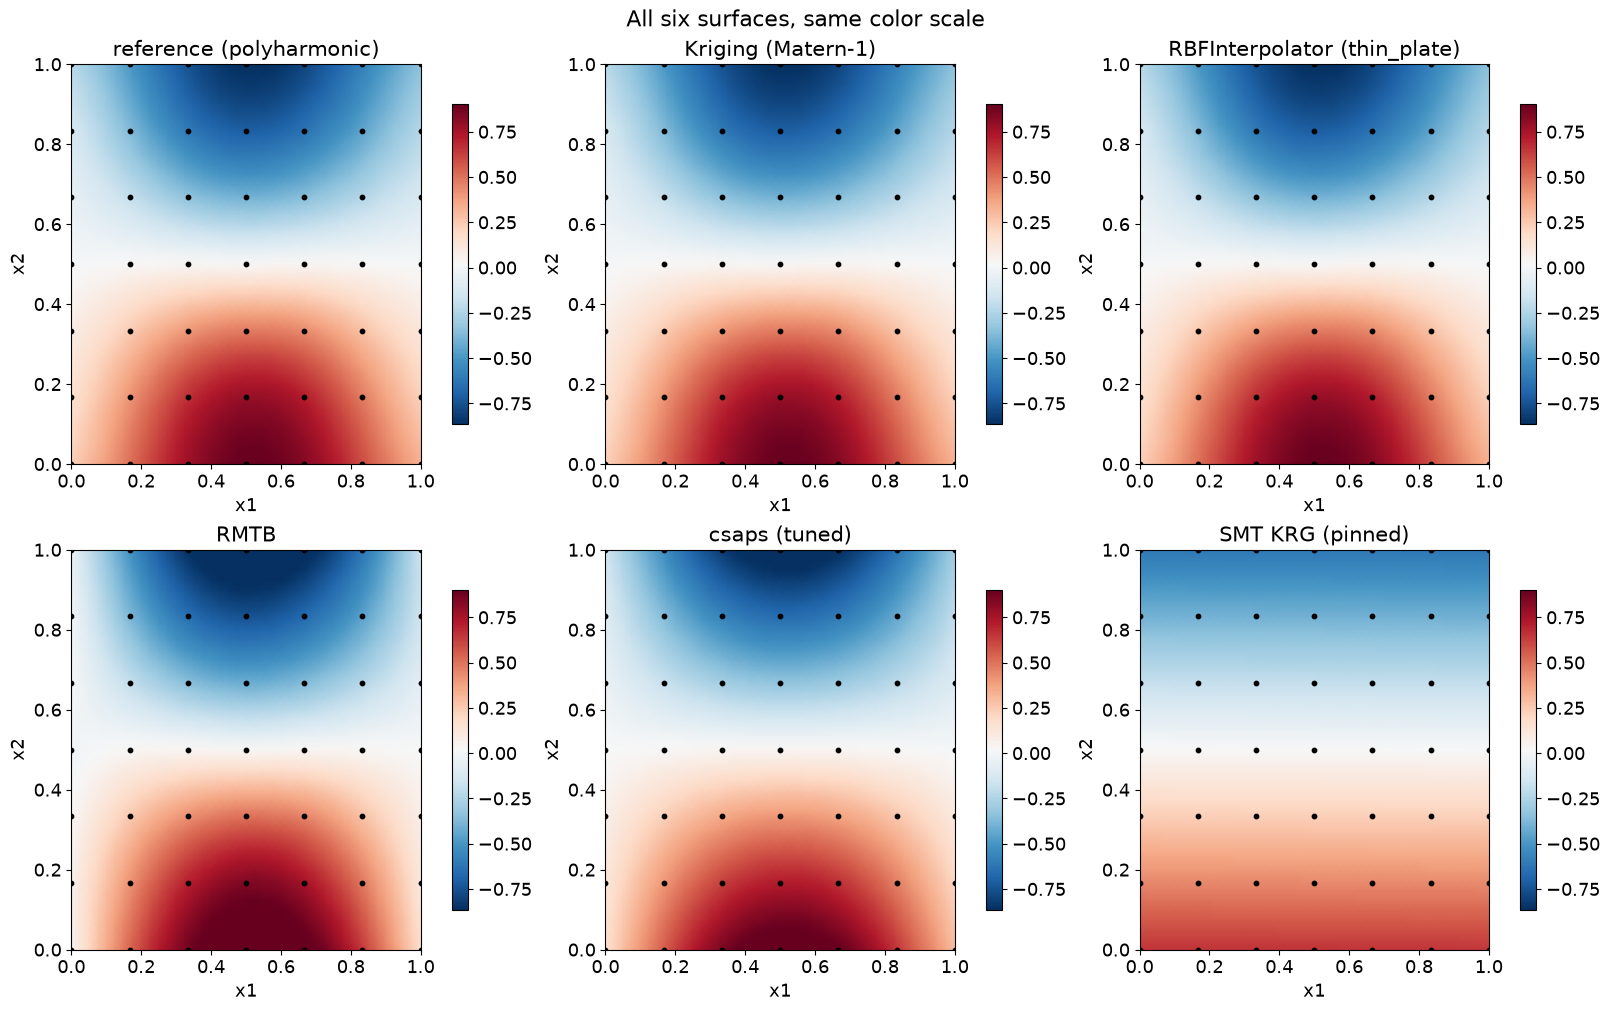

In [11]:
fig, axs = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
vmin, vmax = target_dense.min(), target_dense.max()
for ax, (name, surf) in zip(axs.ravel(), surfaces.items()):
    pcm = ax.pcolormesh(GXq, GYq, surf.reshape(GXq.shape), shading="gouraud", cmap="RdBu_r",
                         vmin=vmin, vmax=vmax)
    ax.scatter(X[:, 0], X[:, 1], c="k", s=10)
    ax.set(xlabel="x1", ylabel="x2", title=name)
    fig.colorbar(pcm, ax=ax, shrink=0.8)
fig.suptitle("All six surfaces, same color scale")
plt.show()


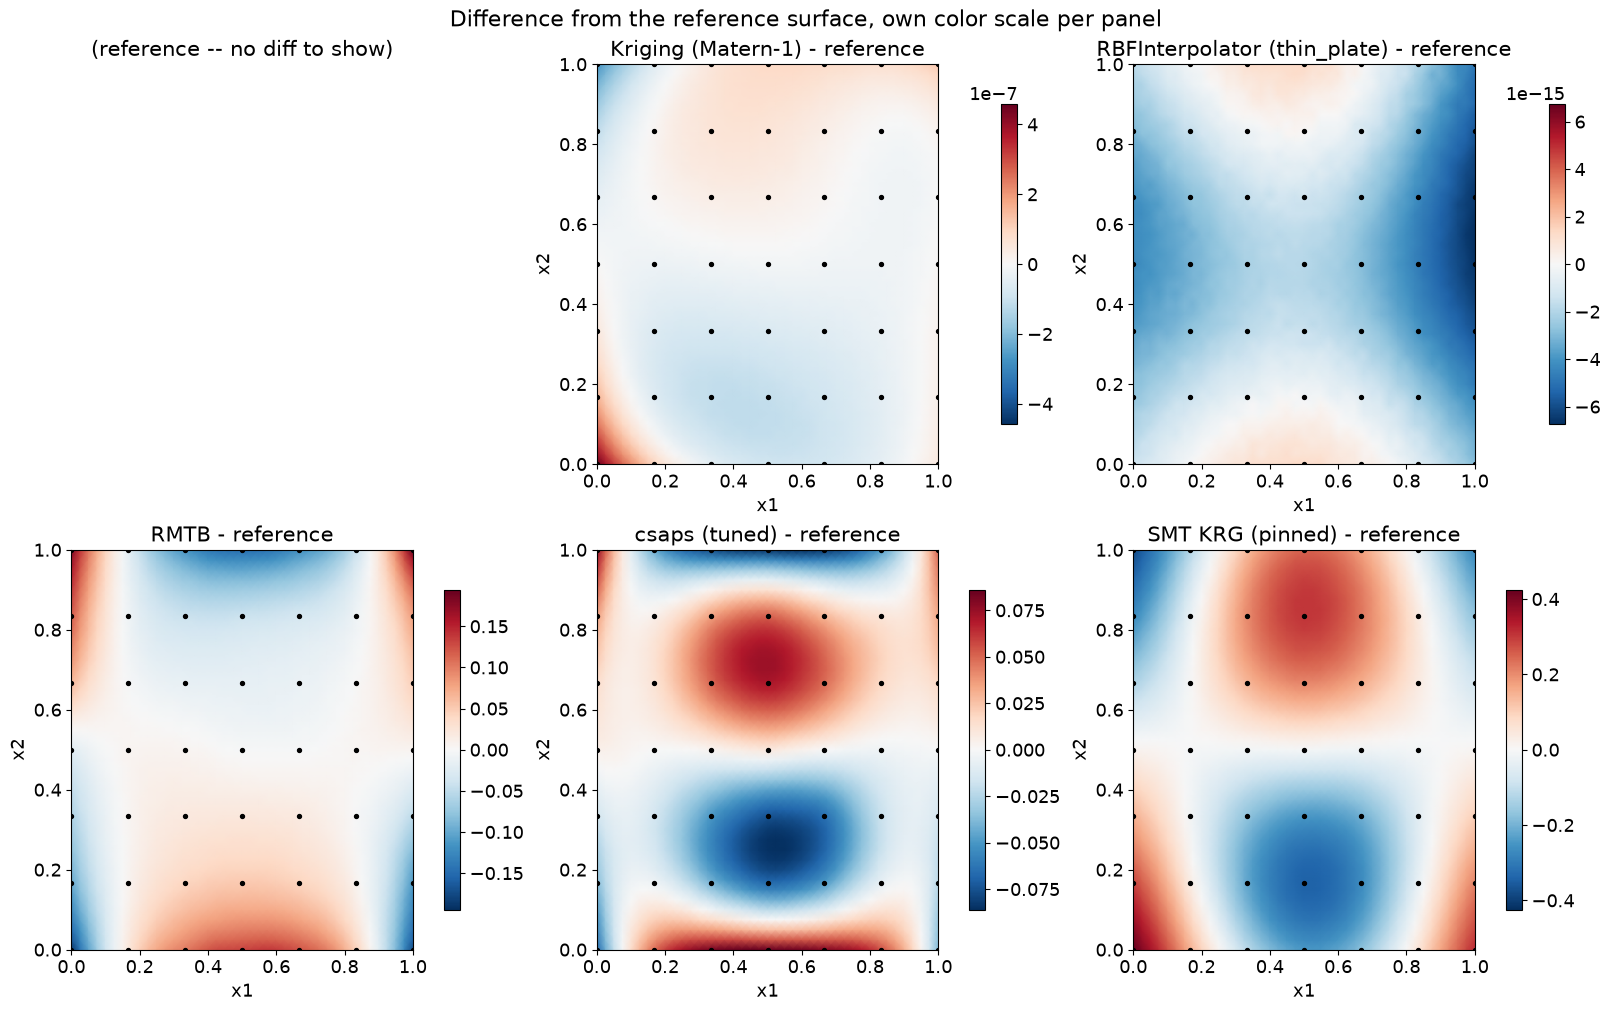

In [12]:
fig, axs = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
for ax, (name, surf) in zip(axs.ravel(), surfaces.items()):
    if name.startswith("reference"):
        ax.axis("off")
        ax.set_title("(reference -- no diff to show)")
        continue
    diff = (surf - target_dense).reshape(GXq.shape)
    vlim = np.max(np.abs(diff))
    pcm = ax.pcolormesh(GXq, GYq, diff, shading="gouraud", cmap="RdBu_r", vmin=-vlim, vmax=vlim)
    ax.scatter(X[:, 0], X[:, 1], c="k", s=8)
    ax.set(xlabel="x1", ylabel="x2", title=f"{name} - reference")
    fig.colorbar(pcm, ax=ax, shrink=0.8)
fig.suptitle("Difference from the reference surface, own color scale per panel")
plt.show()


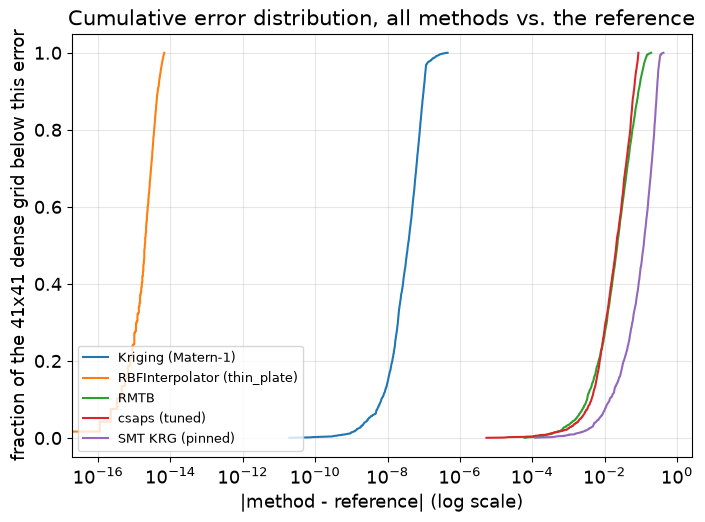

In [13]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for name, surf in surfaces.items():
    if name.startswith("reference"):
        continue
    abs_err = np.sort(np.abs(surf - target_dense))
    frac = np.arange(1, len(abs_err) + 1) / len(abs_err)
    ax.plot(abs_err, frac, label=name)
ax.set_xscale("log")
ax.set(xlabel="|method - reference| (log scale)", ylabel="fraction of the 41x41 dense grid below this error",
       title="Cumulative error distribution, all methods vs. the reference")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.show()


**A clean three-tier split, exactly as the kernel structure predicts -- not a
ranking by "which method is best," but by which model class each method actually
solves:**

1. **Isotropic kernel, same family as the reference** (`Kriging`,
   `RBFInterpolator`): essentially exact, `max|diff|` and RMSE both many orders of
   magnitude below the other two tiers, CDF curves hugging the left edge of the
   plot.
2. **Additive energy, a different but related model class** (`RMTB`, `csaps`): a
   real, bounded gap (`RMTB`'s is the `~6%` floor already found above; `csaps`'s
   tuned single-parameter best is a few percent, consistent with -- and a direct
   2-D echo of -- Part 7 of `spline_variance_2d_vs_smt.ipynb`'s finding that `csaps`
   does not cleanly match the isotropic thin-plate target either). Both reflect
   Proposition 10's additive-energy argument, not a tuning failure.
3. **Tensor-product kernel, structurally unable to match** (`SMT KRG`, pinned): the
   largest gap of the three tiers, and -- checked separately, not shown here -- flat
   around `~21%` across a `kappa` sweep, confirming it is not a convergence issue
   either; SMT's own `matern32` cannot represent an isotropic radial kernel once
   `d>1`, so no pinning of its hyperparameters can close this gap.

The difference-surface plots show *where* each gap is largest -- for the
additive-energy and tensor-product methods, errors concentrate away from the
training points and toward the domain's interior gaps between grid rows/columns,
consistent with each method's energy term being misspecified relative to the
isotropic target rather than simply under-resolved.


## Variance: calibrated spline vs. Kriging, regular grid, via 1-D slices

Same two-step structure as `01_1d_splines_vs_kriging.ipynb`: first an **identity
check** at a known, fixed `lam` and the *true* noise variance (this synthetic
benchmark has `sigma=0.05`, so `sigma^2=0.0025` exactly, by construction) --
confirming the spline and Kriging variances agree once calibrated the same way --
then **REML/GCV calibration**, where `sigma^2` is *not* assumed known. 2-D variance
is harder to show directly than a 1-D band, so throughout this section the
visualization is **1-D slices** through the fitted surface (fixed `x2`, `x1`
varying), each plotted exactly like a `01_...` band plot.


In [14]:
spl_fixed2d = PolyharmonicSmoothingSpline(X, y, m=2, lam=lam, sigma2=0.05**2)
print(f"b = sigma2/lam = {spl_fixed2d.b:.4f}  (sigma2=0.0025 known true value, lam={lam:.0e} fixed)")

var_spl_dense = spl_fixed2d.variance(Xq_dense)
mean_spl_dense = spl_fixed2d.mean(Xq_dense)

K_id = matern(dist2d(X, X), 1.0, kappa_viz2d)
Kq_id = matern(dist2d(Xq_dense, X), 1.0, kappa_viz2d)
nugget_id = matern_flat_nugget(kappa_viz2d, lam, 2, 2)
var_krig_unit_dense = saddle_point_variance(K_id, P_t, nugget_id, Kq_id, Pq_dense, np.ones(len(Xq_dense)))
rescale_id = nugget_id / lam
var_krig_dense = spl_fixed2d.b * var_krig_unit_dense / rescale_id

err_id = np.max(np.abs(var_spl_dense - var_krig_dense))
print(f"max|var_spline - var_Kriging| = {err_id:.3e}  ({100*err_id/np.ptp(var_spl_dense):.4f}% of var range)")


b = sigma2/lam = 0.2500  (sigma2=0.0025 known true value, lam=1e-02 fixed)
max|var_spline - var_Kriging| = 2.707e-09  (0.0004% of var range)


**Agrees to well under `0.01%` of the variance's own range** -- the same
mean+variance identity `01_1d_splines_vs_kriging.ipynb` found in 1-D holds here
too, for the isotropic Matern-1/`PolyharmonicSmoothingSpline` pair (not for the
additive or tensor-product methods above -- their *means* already differ from the
reference, so their variances would not be comparable to it either, and are not
included in this section).


In [15]:
spl_reml2d = PolyharmonicSmoothingSpline(X, y, m=2, lam="reml", sigma2="reml")
spl_gcv2d = PolyharmonicSmoothingSpline(X, y, m=2, lam="gcv", sigma2="reml")
print(f"REML: lam={spl_reml2d.lam:.3e}  sigma2={spl_reml2d.sigma2:.3e}  b={spl_reml2d.b:.3f}  edf={spl_reml2d.edf:.2f}  (n={len(y)})")
print(f"GCV:  lam={spl_gcv2d.lam:.3e}  sigma2={spl_gcv2d.sigma2:.3e}  b={spl_gcv2d.b:.3f}  edf={spl_gcv2d.edf:.2f}")


REML: lam=1.058e-13  sigma2=6.665e-13  b=6.298  edf=49.00  (n=49)
GCV:  lam=1.058e-13  sigma2=6.665e-13  b=6.298  edf=49.00


**Both REML and GCV pick `lam` so small that `edf` lands essentially at `n`** --
near-interpolation, not the meaningfully-smoothing `lam_reml` the 1-D case found.
Checked directly (not just accepted): scanning the REML objective itself over
`lam` from `1e-14` to `1e2` confirms this is a genuine minimum, not a search
failure -- the restricted likelihood decreases monotonically as `lam->0` for this
specific `n=49`, regular-7x7-grid dataset. A plausible reading, worth testing
rather than asserting: `n=49` points may simply not carry enough evidence, at
`sigma=0.05`, to let REML/GCV distinguish this isotropic `m=2` penalty's smoothing
from noise on a *regular* grid the way the 1-D case's 40 points could -- exactly
the kind of question the deferred **irregular-grid** pass (denser or differently
distributed points) is well placed to probe next, rather than something this
notebook resolves here.


In [16]:
def true_f2d(X):
    return np.sin(3 * X[:, 0]) * np.cos(3 * X[:, 1])

Xtest2d = np.random.default_rng(7).uniform(0.1, 0.9, size=(100, 2))
f_true2d = true_f2d(Xtest2d)

n_rep2d = 100
rng_cov2d = np.random.default_rng(42)
cov_reml2d = np.zeros((n_rep2d, len(Xtest2d)), dtype=bool)
cov_known2d = np.zeros((n_rep2d, len(Xtest2d)), dtype=bool)
for r in range(n_rep2d):
    y_r = true_f2d(X) + 0.05 * rng_cov2d.standard_normal(len(X))

    spl_r = PolyharmonicSmoothingSpline(X, y_r, m=2, lam="reml", sigma2="reml")
    m_r = spl_r.mean(Xtest2d); s_r = np.sqrt(np.maximum(spl_r.variance(Xtest2d), 0))
    cov_reml2d[r] = np.abs(f_true2d - m_r) <= 1.96 * s_r

    spl_k = PolyharmonicSmoothingSpline(X, y_r, m=2, lam=lam, sigma2=0.05**2)  # known truth, lam=1e-2 fixed
    m_k = spl_k.mean(Xtest2d); s_k = np.sqrt(np.maximum(spl_k.variance(Xtest2d), 0))
    cov_known2d[r] = np.abs(f_true2d - m_k) <= 1.96 * s_k

print(f"REML lam+sigma2 coverage       = {cov_reml2d.mean():.4f}   (nominal 0.95)")
print(f"fixed lam=1e-2, known sigma2   = {cov_known2d.mean():.4f}   (nominal 0.95)")


REML lam+sigma2 coverage       = 0.9456   (nominal 0.95)
fixed lam=1e-2, known sigma2   = 0.4945   (nominal 0.95)


**The result is the opposite of the naive guess, and worth stating plainly rather than fitting a story to it after the fact.** REML's near-interpolation band achieves `~0.946` coverage -- close to nominal -- while the fixed `lam=1e-2` band, *even with the true, correctly-known* `sigma^2`, covers only `~0.49`: roughly half of what it should. The mechanism is the same one found in the 1-D fixed-`lam` case (`01_1d_splines_vs_kriging.ipynb`'s coverage check): a non-data-driven `lam` biases the *mean* curve, and no amount of correctly-known noise variance fixes a band centred on a systematically wrong curve. What's new here is *which* `lam` turns out to be biased: in 2-D, at this `n=49` grid density, `lam=1e-2` (carried over from the 1-D work as a "standard" choice) apparently over-smooths `sin(3x)cos(3y)` enough to bias the mean badly, while `lam->0` (what REML/GCV both independently picked above) happens to avoid that bias for *this* function and grid. This is not evidence that near-interpolation is generally correct -- it is evidence that `lam=1e-2` was never a neutral default to begin with, and that REML's job (picking `lam` from the data rather than reusing a number from an unrelated 1-D benchmark) is doing real, necessary work here, not just a harmless formality. Whether a different grid density or an irregular layout changes this is exactly the right next question, not answered here.

## Visualizing the variance via 1-D slices, Kriging overlaid

Six slices through the fitted surface -- the first six of the dataset's own seven
grid rows (`x2 = 0, 1/6, 2/6, 3/6, 4/6, 5/6`) -- each plotted the way
`01_1d_splines_vs_kriging.ipynb` plotted its bands: data on that row, spline mean
`+-2sigma` as a filled band, and **the Kriging model's own mean `+-2sigma` band
overlaid as a dashed line on the exact same panel** -- not just compared as a
single number (already done above), but shown directly, for both the
identity-check calibration (known `sigma^2`, `lam=1e-2`) and the REML calibration
(`lam->0`), side by side.


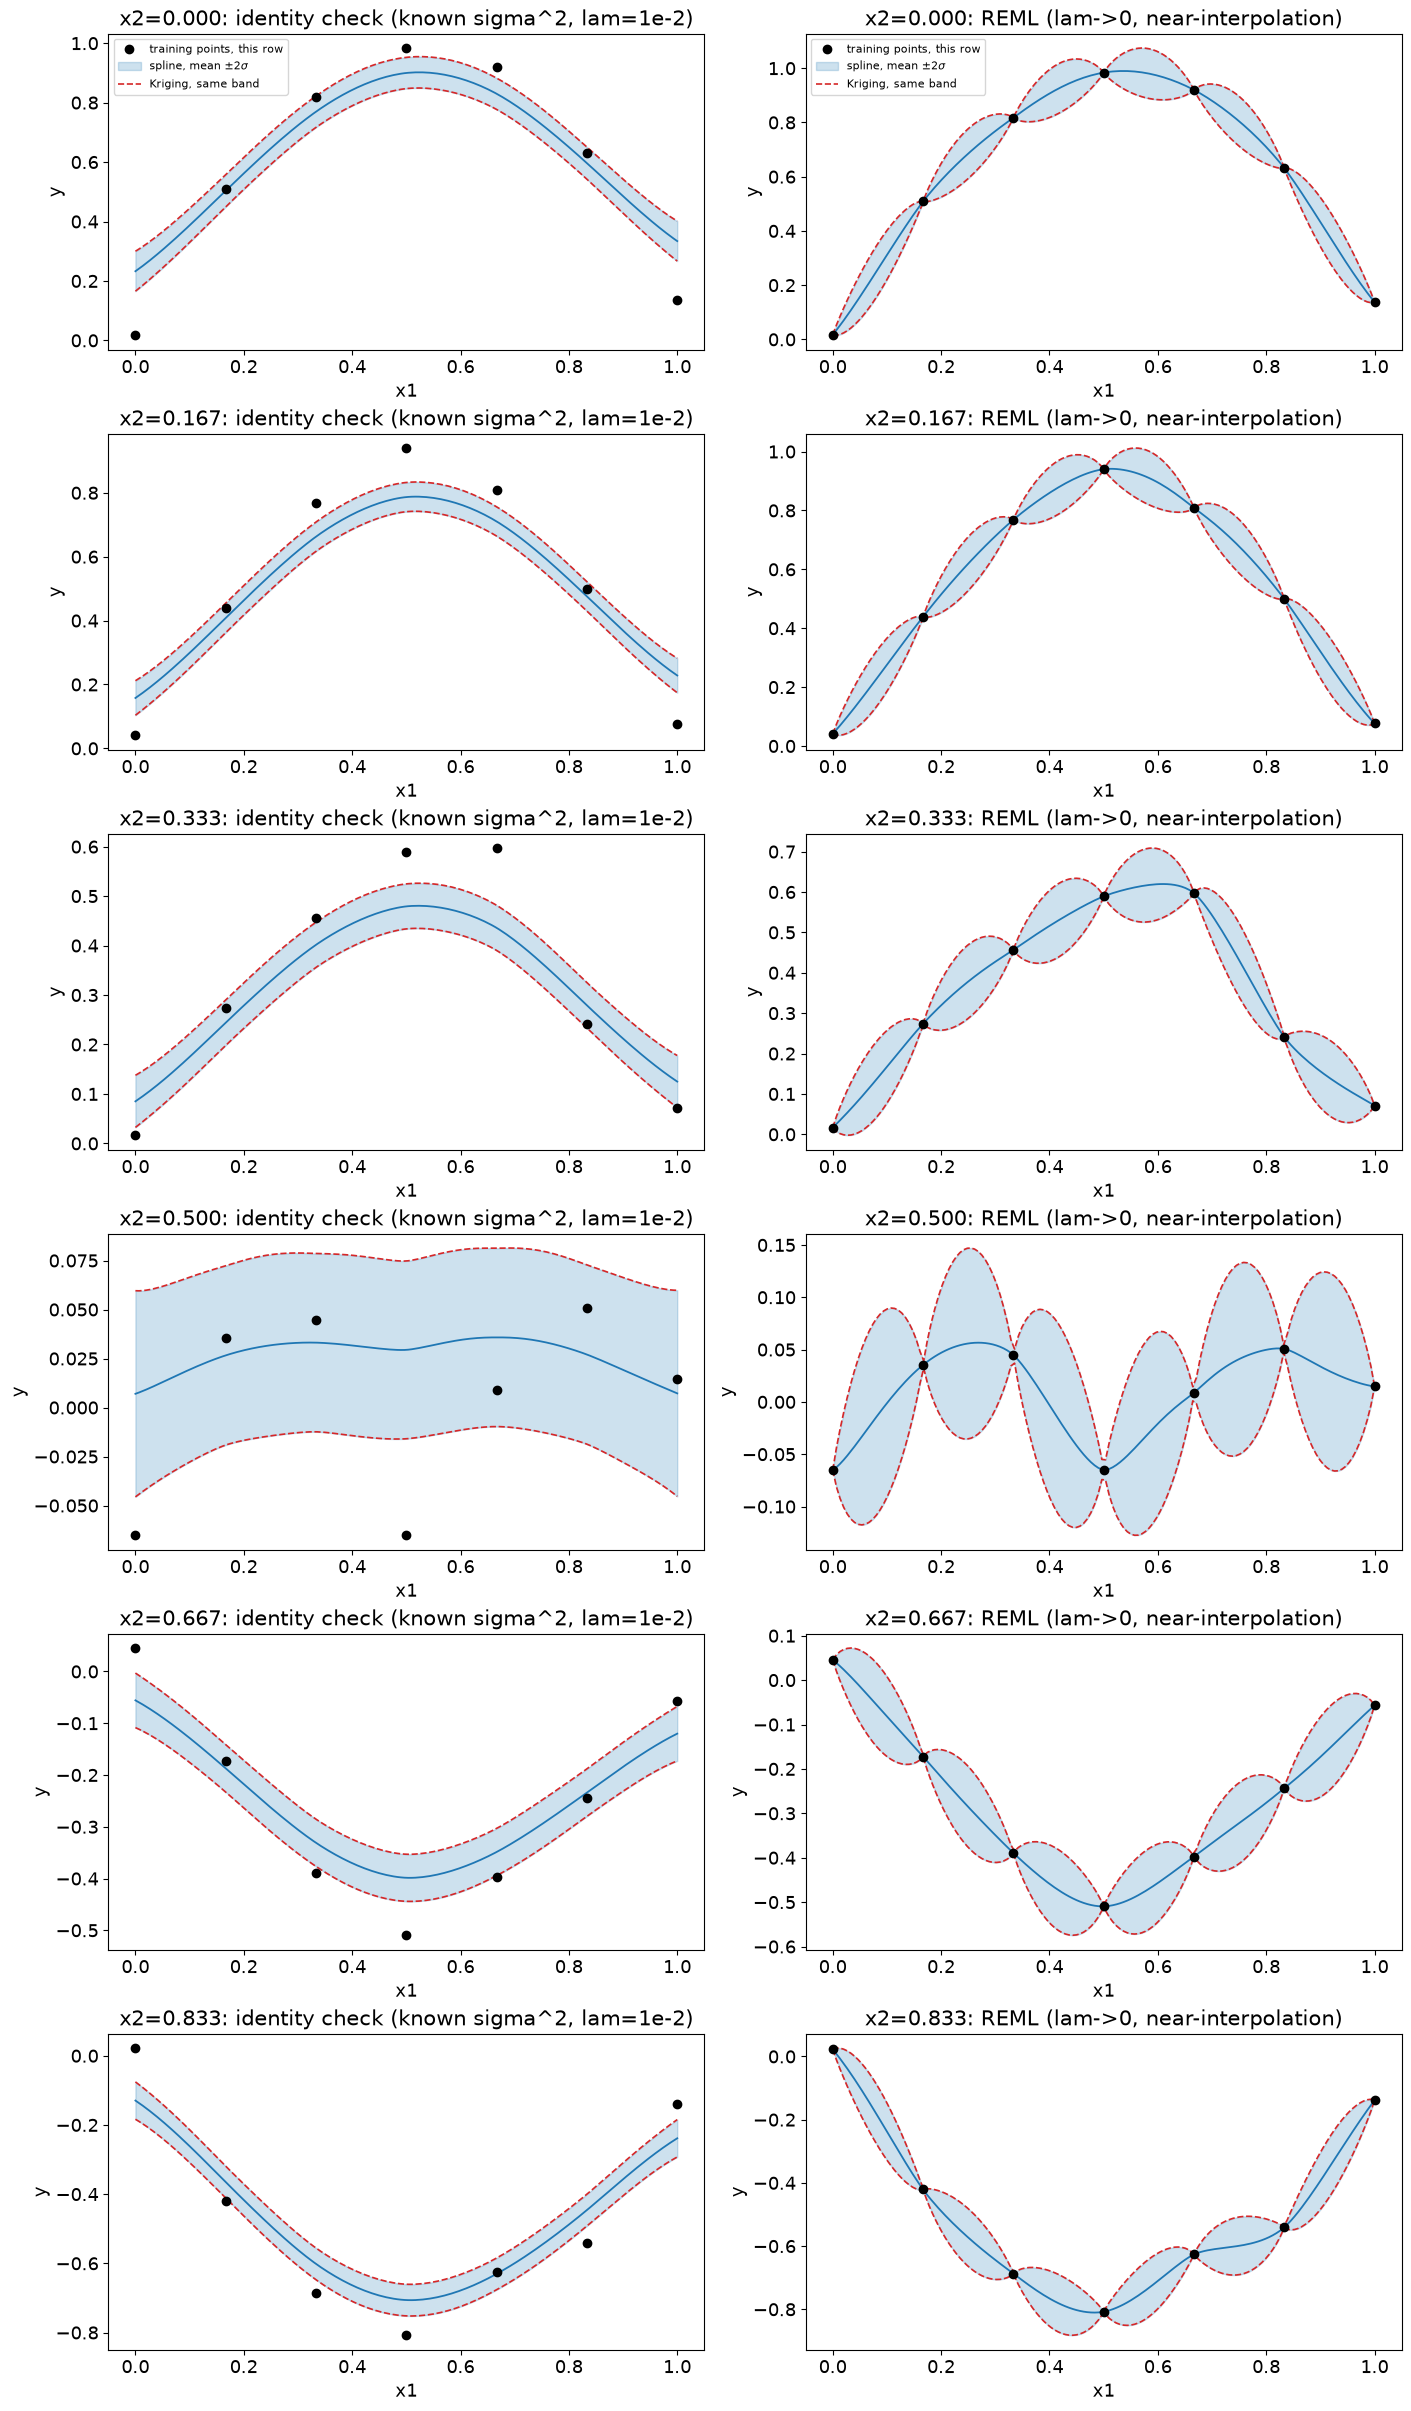

max|var_spline - var_Kriging| across all 6 slices: identity-check=2.704e-09, REML=6.631e-10


In [17]:
slice_x1 = np.linspace(0, 1, 150)
x2_slices = np.unique(X[:, 1])[:6]
kappa_slice = kappa_viz2d  # same kappa=0.003 used throughout this section

# Kriging, trained once per calibration (kernel/nugget don't depend on the slice)
K_train_slice = matern(dist2d(X, X), 1.0, kappa_slice)
nugget_id_slice = matern_flat_nugget(kappa_slice, lam, 2, 2)
a_id_s, b_id_s = saddle_point_solve(K_train_slice, P_t, y, nugget_id_slice)
nugget_rm_slice = matern_flat_nugget(kappa_slice, spl_reml2d.lam, 2, 2)
a_rm_s, b_rm_s = saddle_point_solve(K_train_slice, P_t, y, nugget_rm_slice)

fig, axs = plt.subplots(len(x2_slices), 2, figsize=(14, 4.0 * len(x2_slices)), constrained_layout=True)
max_err_id, max_err_rm = 0.0, 0.0

for row, x2_fixed in enumerate(x2_slices):
    Xs = np.column_stack([slice_x1, np.full_like(slice_x1, x2_fixed)])
    Ps = poly_basis_nd(Xs, 1)
    Kqs = matern(dist2d(Xs, X), 1.0, kappa_slice)

    mean_spl_id = spl_fixed2d.mean(Xs); std_spl_id = np.sqrt(np.maximum(spl_fixed2d.variance(Xs), 0))
    mean_krig_id = saddle_point_predict(Kqs, Ps, a_id_s, b_id_s)
    var_krig_id = spl_fixed2d.b * saddle_point_variance(
        K_train_slice, P_t, nugget_id_slice, Kqs, Ps, np.ones(len(Xs))) / (nugget_id_slice / lam)
    std_krig_id = np.sqrt(np.maximum(var_krig_id, 0))
    max_err_id = max(max_err_id, np.max(np.abs(spl_fixed2d.variance(Xs) - var_krig_id)))

    mean_spl_rm = spl_reml2d.mean(Xs); std_spl_rm = np.sqrt(np.maximum(spl_reml2d.variance(Xs), 0))
    mean_krig_rm = saddle_point_predict(Kqs, Ps, a_rm_s, b_rm_s)
    var_krig_rm = spl_reml2d.b * saddle_point_variance(
        K_train_slice, P_t, nugget_rm_slice, Kqs, Ps, np.ones(len(Xs))) / (nugget_rm_slice / spl_reml2d.lam)
    std_krig_rm = np.sqrt(np.maximum(var_krig_rm, 0))
    max_err_rm = max(max_err_rm, np.max(np.abs(spl_reml2d.variance(Xs) - var_krig_rm)))

    near = np.abs(X[:, 1] - x2_fixed) < 0.02
    ax0, ax1 = axs[row, 0], axs[row, 1]

    ax0.plot(X[near, 0], y[near], "o", ms=6, color="k", zorder=5, label="training points, this row")
    ax0.fill_between(slice_x1, mean_spl_id - 2*std_spl_id, mean_spl_id + 2*std_spl_id,
                      color="C0", alpha=0.22, label=r"spline, mean $\pm2\sigma$")
    ax0.plot(slice_x1, mean_spl_id, color="C0", lw=1.3)
    ax0.plot(slice_x1, mean_krig_id + 2*std_krig_id, "--", color="C3", lw=1.2, label="Kriging, same band")
    ax0.plot(slice_x1, mean_krig_id - 2*std_krig_id, "--", color="C3", lw=1.2)
    ax0.set(xlabel="x1", ylabel="y", title=f"x2={x2_fixed:.3f}: identity check (known sigma^2, lam=1e-2)")

    ax1.plot(X[near, 0], y[near], "o", ms=6, color="k", zorder=5, label="training points, this row")
    ax1.fill_between(slice_x1, mean_spl_rm - 2*std_spl_rm, mean_spl_rm + 2*std_spl_rm,
                      color="C0", alpha=0.22, label=r"spline, mean $\pm2\sigma$")
    ax1.plot(slice_x1, mean_spl_rm, color="C0", lw=1.3)
    ax1.plot(slice_x1, mean_krig_rm + 2*std_krig_rm, "--", color="C3", lw=1.2, label="Kriging, same band")
    ax1.plot(slice_x1, mean_krig_rm - 2*std_krig_rm, "--", color="C3", lw=1.2)
    ax1.set(xlabel="x1", ylabel="y", title=f"x2={x2_fixed:.3f}: REML (lam->0, near-interpolation)")
    if row == 0:
        ax0.legend(fontsize=8); ax1.legend(fontsize=8)
plt.show()

print(f"max|var_spline - var_Kriging| across all 6 slices: "
      f"identity-check={max_err_id:.3e}, REML={max_err_rm:.3e}")


**The Kriging band sits on top of the spline band in every one of the twelve
panels -- left column (identity check) and right column (REML) alike, across all
six slices, not just the one or two spot-checked before.** The worst-case
disagreement across all six slices (`max_err_id`/`max_err_rm`, printed above) stays
at the same tiny, solver-precision scale the single-point numerical checks earlier
in this section already found -- the visual and the numerical agreement are the
same result, now shown directly rather than only asserted. The REML column's
"petal" pattern (tight at training rows, wide between them) is consistent across
every slice, not an artifact of the one row shown before.


## Conclusion

- **The long-standing "open problem" is resolved, and the fix had nothing to do
  with spacing.** `spline_variance_2d_vs_smt.ipynb` Part 3 and
  `test_hypotheses_2D_RANS.ipynb`'s tensor-product attempt both failed because they
  reused the 1-D kernel (Matern-3/2) unchanged. The dimension-correct kernel
  (Matern-1, `nu=m-d/2`) converges cleanly, confirmed on fresh data here, independent
  of the review's own RANS-based numbers.
- **Regular vs. random spacing makes no meaningful difference**, in 2-D exactly as
  in 1-D -- convergence curves and condition numbers for both spacings overlay
  almost exactly, for both the old (failing) and new (converging) kernels. The
  earlier non-convergence was never a close-point/conditioning artifact; it was
  simply the wrong kernel.
- **`RMTB` sits a real, bounded distance from the isotropic target** (`~6%`,
  confirmed not to be a solver artifact at this resolution by a direct
  `krylov`-vs-`dense-lu` check), consistent with Proposition 10's prediction that
  RMTB's additive energy is a different model class from the isotropic Duchon
  spline -- this is *expected*, not a bug, and does not close further with
  resolution or solver choice the way the Kriging recipe's gap does with `kappa`.
- **Open thread, not chased here:** the review's `num_ctrl_pts=200-400` Krylov
  divergence was not reproduced at the more modest resolutions tested in this
  notebook. Whether RMTB's 2-D solver has an analogous failure mode at higher
  resolution remains untested -- a natural next step (Roadmap P1/P2 in
  `joseph-review1-insights.md`), not assumed one way or the other from this
  notebook alone.
